In [1]:
import pandas as pd

In [2]:
data = pd.read_csv('../dataset.csv')

In [3]:
data.head()

,id,lhs,rhs,tablename,is_approx,null_eq_nul,is_genuine
0,0,DepTime,ArrDel15,croppedairline.csv,True,True,False
1,1,ArrTime,ArrDel15,croppedairline.csv,True,True,False
2,2,TailNum,ArrDel15,croppedairline.csv,True,True,False
3,3,ActualElapsedTime,ArrDel15,croppedairline.csv,True,True,False
4,4,AirTime,ArrDel15,croppedairline.csv,True,True,False


In [12]:
data['tablename'].unique()

array(['croppedairline.csv', 'mondialjoin.csv', 'northwind.csv',
       'financial.csv', 'women_basketball.csv'], dtype=object)

In [13]:
tablename_to_path = {
    'croppedairline.csv' : 'croppedairline_sampledoveruniqueid.csv', 
    # 'mondialjoin.csv', 
    'northwind.csv' : 'NW_OCEP.csv',
    'financial.csv': 'financial.csv', 
    'women_basketball.csv':'womensbasketball.csv'
}

In [17]:
tablename_to_df = {}
path_to_data = '../data/'

for name, path in tablename_to_path.items():
    tablename_to_df[name] = pd.read_csv(path_to_data + path)



In [31]:
tablename_to_df['croppedairline.csv'].columns

Index(['Year', 'Quarter', 'Month', 'DayofMonth', 'DayOfWeek', 'FlightDate',
       'UniqueCarrier', 'AirlineID', 'Carrier', 'TailNum', 'FlightNum',
       'OriginAirportID', 'OriginAirportSeqID', 'OriginCityMarketID', 'Origin',
       'OriginCityName', 'OriginState', 'OriginStateFips', 'OriginStateName',
       'OriginWac', 'DestAirportID', 'DestAirportSeqID', 'DestCityMarketID',
       'Dest', 'DestCityName', 'DestState', 'DestStateFips', 'DestStateName',
       'DestWac', 'CRSDepTime', 'DepTime', 'DepDelay', 'DepDelayMinutes',
       'DepDel15', 'DepartureDelayGroups', 'DepTimeBlk', 'TaxiOut', 'TaxiIn',
       'CRSArrTime', 'ArrTime', 'ArrDelay', 'ArrDelayMinutes', 'ArrDel15',
       'ArrivalDelayGroups', 'ArrTimeBlk', 'Cancelled', 'CancellationCode',
       'Diverted', 'CRSElapsedTime', 'ActualElapsedTime', 'AirTime', 'Flights',
       'Distance', 'DistanceGroup', 'CarrierDelay', 'WeatherDelay', 'NASDelay',
       'SecurityDelay', 'LateAircraftDelay', 'FirstDepTime', 'TotalAddGTime'

# Compute LHS apperance of unique values

In [41]:
table_to_map = {
    "northwind.csv": {},
    "financial.csv": {},
    "women_basketball.csv": {},
    "croppedairline.csv": {},
}

for _, row in data.iterrows():
    tablename = row["tablename"]

    if tablename in table_to_map:
        lhs_string = row["lhs"]
        columns = [attr.strip() for attr in lhs_string.split(",") if attr.strip()]

        missing = [c for c in columns if c not in tablename_to_df[tablename].columns]
        if missing:
            for c in missing:
                print(f"could not find {c} in table {tablename}")
            continue

        counts = (
            tablename_to_df[tablename]
            .groupby(columns)
            .size()
            .to_numpy()
        )

        # store counts keyed by the actual lhs_string (or use tuple(columns) if you prefer)
        table_to_map[tablename][lhs_string] = counts


In [42]:
table_to_map

{'northwind.csv': {'CustomerID': array([ 12,  10,  17,  30,  52,  14,  26,   6,  44,  35,  22,  11,   2,
          22,  10,   7,  10,   9,  21, 102,  19,  16,  45,  48,   6,  10,
          20,   8,  26,  19,  22,   4,  32,  45,   9,  55,  23,  39,  11,
          31,   8,   2,  39,  10,  34,  35,  14,  21,  17,  32,  11,   6,
          11,  24,  29,  14,  23,  10,  24,  40,  86,  12,  71,  22,  27,
          30,  14,  16, 116,  26,  15,   6,  20,  39,   7,   8,  14,  29,
          13,   9,  31,  25,  10,  26,  37,  19,  40,  17,  16]),
  'ProductID': array([38, 44, 12, 20, 10, 12, 29, 13,  5, 33, 38, 14, 40, 22,  6, 43, 37,
         27, 37, 16, 39, 14, 20, 51, 18, 32,  9, 33, 32, 32, 51, 15, 32, 19,
         36, 31,  6, 24, 30, 41, 47, 30, 28, 24, 14, 27, 21,  6, 21, 10, 39,
         29, 30, 36, 33, 50, 23, 18, 54, 51, 24, 48, 17, 30, 32,  8, 10, 34,
         31, 39, 42, 38, 14, 13, 46, 39, 38]),
  'EmployeeID': array([345, 241, 321, 420, 117, 168, 176, 260, 107]),
  'OrderID': array([ 

# Compute props of rhs

In [45]:
SUPPORTED_TABLES = {
    "northwind.csv",
    "financial.csv",
    "women_basketball.csv",
    "croppedairline.csv",
}

# lookup: lookup[tablename][rhs_string] -> np.ndarray of probabilities
prob_lookup = {t: {} for t in SUPPORTED_TABLES}

for _, row in data.iterrows():
    tablename = row["tablename"]

    # skip unsupported tables
    if tablename not in prob_lookup or tablename not in tablename_to_df:
        continue

    df_tbl = tablename_to_df[tablename]

    # parse RHS columns
    rhs_string = row["rhs"]
    rhs_cols = [c.strip() for c in str(rhs_string).split(",") if c.strip()]

    if not rhs_cols:
        continue

    # validate RHS columns
    missing = [c for c in rhs_cols if c not in df_tbl.columns]
    if missing:
        for c in missing:
            print(f"could not find RHS column {c} in table {tablename}")
        continue

    # compute probabilities of RHS value combinations
    probs = (
        df_tbl
        .value_counts(rhs_cols, normalize=True, dropna=False)
        .to_numpy()
    )

    # store only probability array
    prob_lookup[tablename][rhs_string] = probs


In [ ]:
prob_lookup

{'northwind.csv': {'cust_CompanyName': array([0.05382831, 0.04733179, 0.03990719, 0.03294664, 0.02552204,
         0.02412993, 0.02227378, 0.02088167, 0.02088167, 0.02041763,
         0.01856148, 0.01856148, 0.01809745, 0.01809745, 0.01809745,
         0.01716937, 0.0162413 , 0.0162413 , 0.01577726, 0.01484919,
         0.01484919, 0.01438515, 0.01438515, 0.01392111, 0.01392111,
         0.01345708, 0.01345708, 0.012529  , 0.01206497, 0.01206497,
         0.01206497, 0.01206497, 0.01160093, 0.01113689, 0.01113689,
         0.01067285, 0.01067285, 0.01020882, 0.01020882, 0.01020882,
         0.01020882, 0.00974478, 0.00974478, 0.00928074, 0.00928074,
         0.00881671, 0.00881671, 0.00881671, 0.00788863, 0.00788863,
         0.00788863, 0.00742459, 0.00742459, 0.00742459, 0.00696056,
         0.00649652, 0.00649652, 0.00649652, 0.00649652, 0.00649652,
         0.00603248, 0.00556845, 0.00556845, 0.00510441, 0.00510441,
         0.00510441, 0.00510441, 0.00464037, 0.00464037, 0.0046403

# Finally compute and export mapping: lhs -> score

In [55]:
import numpy as np
from scipy.special import logsumexp

def lower_bound_log(max_matches, p_rhs):
    return logsumexp( max_matches * np.log(p_rhs))

def improved_lower_bound(k_matches, p_rhs):
    K = np.float64(len(k_matches))
    result = 0.0
    for m in k_matches:
        result += lower_bound_log(m, p_rhs)
    return result

In [63]:
import numpy as np

# Assumes:
# - data: DataFrame with columns at least ["tablename", "lhs", "rhs"]
# - table_to_map[tablename][lhs_string] -> np.ndarray of k_matches (counts per LHS value-combo)
# - prob_lookup[tablename][rhs_string] -> np.ndarray of p_rhs (probabilities per RHS value-combo)
# - improved_lower_bound is already defined (as you provided)

def _normalize_probs(p: np.ndarray) -> np.ndarray:
    p = np.asarray(p, dtype=np.float64)
    s = p.sum()
    if s <= 0:
        return p
    return p / s

def _clip_probs(p: np.ndarray, eps: float = 1e-300) -> np.ndarray:
    # Avoid log(0); keep in (0, 1]
    p = np.asarray(p, dtype=np.float64)
    return np.clip(p, eps, 1.0)

# Create the new column (numerical value) in `data`
out = np.full(len(data), np.nan, dtype=np.float64)

for i, row in data.iterrows():
    tablename = row["tablename"]
    lhs_string = row["lhs"]
    rhs_string = row["rhs"]

    # skip unsupported / missing lookups
    if tablename not in table_to_map or tablename not in prob_lookup:
        continue
    if lhs_string not in table_to_map[tablename]:
        continue
    if rhs_string not in prob_lookup[tablename]:
        continue

    k_matches = table_to_map[tablename][lhs_string]          # counts array
    p_rhs = prob_lookup[tablename][rhs_string]               # probability array

    k_matches = np.asarray(k_matches, dtype=np.float64)
    p_rhs = _clip_probs(_normalize_probs(p_rhs))

    # Plug into your function
    out[i] = improved_lower_bound(k_matches, p_rhs)

# Add as a new column in data (use whatever name you want)
data["improved_lb_log"] = out


# Visualization

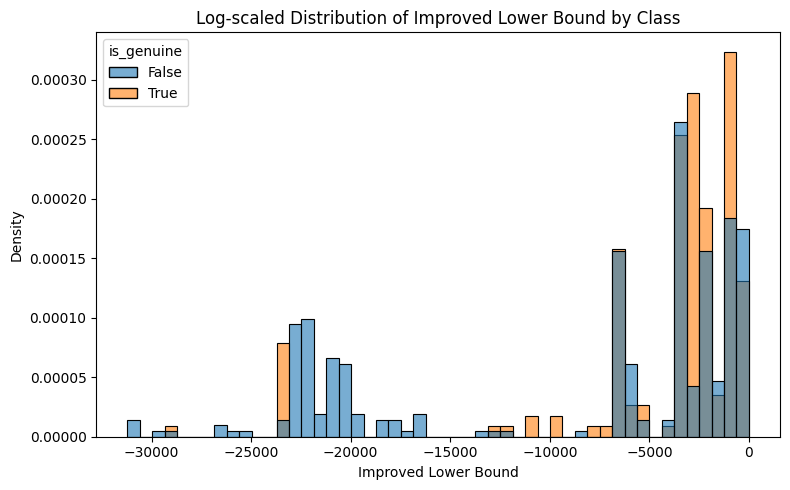

In [ ]:
import seaborn as sns
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 5))

sns.histplot(
    data=data,
    x="improved_lb_log",
    hue="is_genuine",
    bins=50,
    stat="density",      # compare shapes, not raw counts
    common_norm=False,   # each class normalized independently
    alpha=0.6
)

plt.xlabel("Improved Lower Bound")
plt.ylabel("Density")

plt.title("Log-scaled Distribution of Improved Lower Bound by Class")
plt.tight_layout()
plt.show()


In [68]:
cols = ["tablename", "lhs", "rhs", "improved_lb_log"]

lowest_genuine = (
    data.loc[data["is_genuine"] == False, cols]
        .sort_values("improved_lb_log")
        .head(10)
)

lowest_genuine


,tablename,lhs,rhs,improved_lb_log
132,croppedairline.csv,CRSElapsedTime,DepTimeBlk,-31217.788628
134,croppedairline.csv,AirTime,DepTimeBlk,-30805.397598
133,croppedairline.csv,ActualElapsedTime,DepTimeBlk,-30788.325638
128,croppedairline.csv,CRSArrTime,DepTimeBlk,-29665.398875
130,croppedairline.csv,ArrTime,DepTimeBlk,-29121.613311
137,croppedairline.csv,"DepDelay, DayofMonth",DepTimeBlk,-26752.319109
138,croppedairline.csv,"DepDelay, FlightDate",DepTimeBlk,-26752.319109
129,croppedairline.csv,FlightNum,DepTimeBlk,-26049.330837
131,croppedairline.csv,TailNum,DepTimeBlk,-25499.597187
57,croppedairline.csv,"DepTimeBlk, ArrTimeBlk",OriginStateName,-23153.194463


In [71]:
k_matches = table_to_map['croppedairline.csv']['FlightNum']          # counts array
p_rhs = prob_lookup['croppedairline.csv']['DepTimeBlk']               # probability array
print(k_matches)
print(p_rhs)

[10 10  9 ...  2  1  1]
[0.07116667 0.07016667 0.06616667 0.06533333 0.06525    0.06333333
 0.06316667 0.06233333 0.05808333 0.0575     0.05725    0.0565
 0.05475    0.0535     0.05083333 0.02841667 0.02383333 0.01958333
 0.01283333]


In [72]:
k_matches

array([10, 10,  9, ...,  2,  1,  1], shape=(2499,))

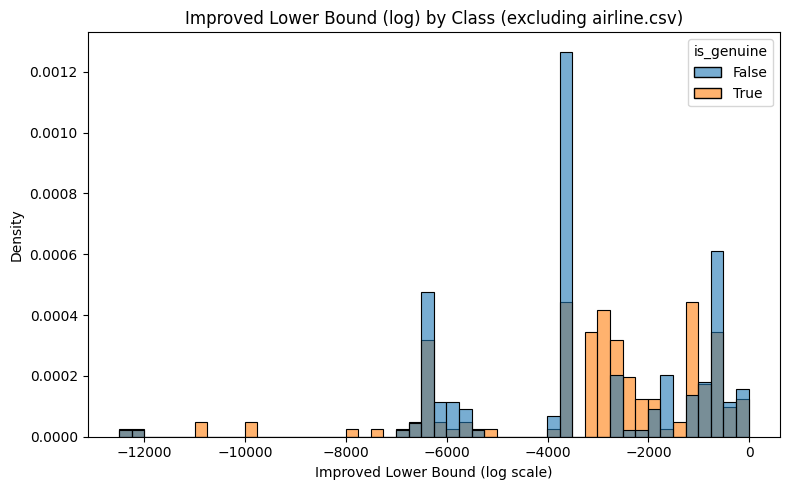

In [69]:
import seaborn as sns
import matplotlib.pyplot as plt

# exclude airline table + keep log-safe, small probabilities
plot_df = data.loc[
    (data["tablename"] != "croppedairline.csv") &        # <-- exclusion
    (data["improved_lb_log"] < np.log(0.1)) &     # log(<0.1)
    (data["improved_lb_log"].notna())
]

plt.figure(figsize=(8, 5))

sns.histplot(
    data=plot_df,
    x="improved_lb_log",
    hue="is_genuine",
    bins=50,
    stat="density",
    common_norm=False,
    alpha=0.6
)

plt.xlabel("Improved Lower Bound (log scale)")
plt.ylabel("Density")
plt.title("Improved Lower Bound (log) by Class (excluding airline.csv)")
plt.tight_layout()
plt.show()


In [75]:
import numpy as np
from scipy.stats import beta, chi2
from scipy.special import betaln
from scipy.optimize import minimize

def _prep_beta_sample(x, eps=1e-12):
    x = np.asarray(x, dtype=np.float64)
    x = x[np.isfinite(x)]
    # beta requires open interval (0,1)
    return np.clip(x, eps, 1.0 - eps)

def beta_mom_init(x, eps=1e-12):
    """
    Method-of-moments initializer for Beta(a,b).
    Robust to small variance; returns positive (a,b).
    """
    x = _prep_beta_sample(x, eps=eps)
    m = float(np.mean(x))
    v = float(np.var(x, ddof=1)) if len(x) > 1 else 0.0

    # If variance is too small, MLE is ill-conditioned; pick a concentrated beta around mean.
    if v <= 1e-18:
        k = 1e6  # very concentrated
        a = max(m * k, 1e-3)
        b = max((1.0 - m) * k, 1e-3)
        return a, b

    # MoM formulas
    t = m * (1.0 - m) / v - 1.0
    if not np.isfinite(t) or t <= 0:
        # fallback to mild concentration
        k = 1000.0
        a = max(m * k, 1e-3)
        b = max((1.0 - m) * k, 1e-3)
        return a, b

    a = max(m * t, 1e-6)
    b = max((1.0 - m) * t, 1e-6)
    return a, b

def beta_mle_robust(x, eps=1e-12):
    """
    Robust MLE for Beta(a,b) with a,b>0 using bounded optimization in log-space.
    """
    x = _prep_beta_sample(x, eps=eps)
    if len(x) < 2:
        # not enough data to fit; return something valid
        return 1.0, 1.0

    a0, b0 = beta_mom_init(x, eps=eps)

    # negative log-likelihood (use stable betaln)
    def nll(log_ab):
        loga, logb = log_ab
        a, b = np.exp(loga), np.exp(logb)
        # -sum logpdf = -[(a-1)sum log x + (b-1)sum log(1-x) - n*logB(a,b)]
        n = x.size
        return -( (a - 1.0) * np.sum(np.log(x))
                + (b - 1.0) * np.sum(np.log1p(-x))
                - n * betaln(a, b) )

    x0 = np.log([a0, b0])

    # bound logs to keep a,b within sane numerical range
    bounds = [(-20, 40), (-20, 40)]  # a,b in ~[2e-9, 2e17]

    res = minimize(nll, x0, method="L-BFGS-B", bounds=bounds)

    if not res.success or not np.isfinite(res.fun):
        # fallback to MoM init if optimizer failed
        return float(a0), float(b0)

    a_hat, b_hat = np.exp(res.x[0]), np.exp(res.x[1])
    return float(a_hat), float(b_hat)

def beta_loglik(x, a, b, eps=1e-12):
    x = _prep_beta_sample(x, eps=eps)
    return float(np.sum(beta.logpdf(x, a, b, loc=0.0, scale=1.0)))

def beta_lrt_two_sample(x_true, x_false, alpha=0.05, eps=1e-12):
    x_true  = _prep_beta_sample(x_true, eps=eps)
    x_false = _prep_beta_sample(x_false, eps=eps)
    x_all   = np.concatenate([x_true, x_false])

    # H1: separate fits
    aT, bT = beta_mle_robust(x_true, eps=eps)
    aF, bF = beta_mle_robust(x_false, eps=eps)
    ll1 = beta_loglik(x_true, aT, bT, eps=eps) + beta_loglik(x_false, aF, bF, eps=eps)

    # H0: pooled fit
    a0, b0 = beta_mle_robust(x_all, eps=eps)
    ll0 = beta_loglik(x_all, a0, b0, eps=eps)

    stat = 2.0 * (ll1 - ll0)
    pval = 1.0 - chi2.cdf(stat, df=2)

    return {
        "stat": stat,
        "p_value": pval,
        "reject_H0_at_95%": (pval < alpha),
        "H0_params": (a0, b0),
        "H1_params_true": (aT, bT),
        "H1_params_false": (aF, bF),
        "n_true": len(x_true),
        "n_false": len(x_false),
    }

# --- Use on your data ---
p = np.exp(data["improved_lb_log"].to_numpy())  # assumes natural log
x_true  = p[data["is_genuine"].to_numpy() == True]
x_false = p[data["is_genuine"].to_numpy() == False]

result = beta_lrt_two_sample(x_true, x_false)
result


{'stat': 6.636024838106096,
 'p_value': np.float64(0.036224759891437586),
 'reject_H0_at_95%': np.True_,
 'H0_params': (0.032252840130552324, 0.1845004323371848),
 'H1_params_true': (0.03341999779988069, 0.26735036443166915),
 'H1_params_false': (0.031820125683387504, 0.16158690287400823),
 'n_true': 183,
 'n_false': 339}

In [ ]:
import pandas as pd
from pathlib import Path

lookup_df = data[["tablename", "lhs", "rhs",'improved_lb_log']].copy()
out_path = Path("../data")
csv_path = out_path / "feature_logprops.csv"
lookup_df.to_csv(csv_path, index=False)
